In [114]:
import torch
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [115]:
x = torch.linspace(-2, 2, 50)
x

tensor([-2.0000, -1.9184, -1.8367, -1.7551, -1.6735, -1.5918, -1.5102, -1.4286,
        -1.3469, -1.2653, -1.1837, -1.1020, -1.0204, -0.9388, -0.8571, -0.7755,
        -0.6939, -0.6122, -0.5306, -0.4490, -0.3673, -0.2857, -0.2041, -0.1224,
        -0.0408,  0.0408,  0.1224,  0.2041,  0.2857,  0.3673,  0.4490,  0.5306,
         0.6122,  0.6939,  0.7755,  0.8571,  0.9388,  1.0204,  1.1020,  1.1837,
         1.2653,  1.3469,  1.4286,  1.5102,  1.5918,  1.6735,  1.7551,  1.8367,
         1.9184,  2.0000])

In [116]:
x = torch.linspace(-2, 2, 120).unsqueeze(1)
x

tensor([[-2.0000],
        [-1.9664],
        [-1.9328],
        [-1.8992],
        [-1.8655],
        [-1.8319],
        [-1.7983],
        [-1.7647],
        [-1.7311],
        [-1.6975],
        [-1.6639],
        [-1.6303],
        [-1.5966],
        [-1.5630],
        [-1.5294],
        [-1.4958],
        [-1.4622],
        [-1.4286],
        [-1.3950],
        [-1.3613],
        [-1.3277],
        [-1.2941],
        [-1.2605],
        [-1.2269],
        [-1.1933],
        [-1.1597],
        [-1.1261],
        [-1.0924],
        [-1.0588],
        [-1.0252],
        [-0.9916],
        [-0.9580],
        [-0.9244],
        [-0.8908],
        [-0.8571],
        [-0.8235],
        [-0.7899],
        [-0.7563],
        [-0.7227],
        [-0.6891],
        [-0.6555],
        [-0.6218],
        [-0.5882],
        [-0.5546],
        [-0.5210],
        [-0.4874],
        [-0.4538],
        [-0.4202],
        [-0.3866],
        [-0.3529],
        [-0.3193],
        [-0.2857],
        [-0.

In [117]:
noise = 0.6 * torch.randn_like(x)
y= 3 * x + 2 + noise

In [118]:
import matplotlib.pyplot as plt

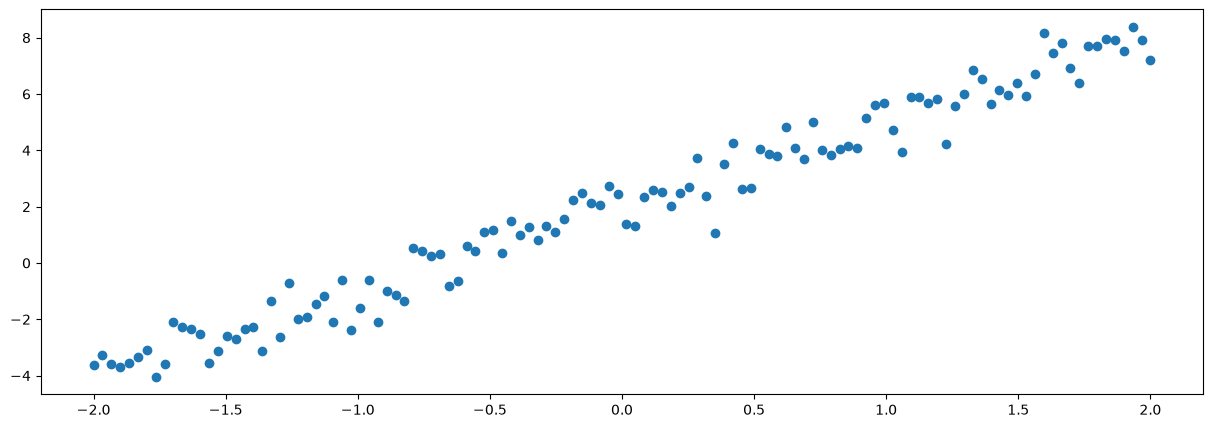

In [119]:
plt.figure(figsize=(15,5)) 
plt.scatter(x,y)

In [120]:
import torch.nn as nn

In [121]:
model = nn.Linear(1,1)

In [122]:
loss_function = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.1)
epochs= 500
losses = []
for epoch in range(epochs):
    y_pred = model(x)
    loss = loss_function(y, y_pred)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    losses.append(loss.item())
    if epoch % 100 == 0:
        print(f"Epoch : {epoch}/{epochs}, loss = {loss.item()}")

Epoch : 0/500, loss = 8.0099458694458
Epoch : 100/500, loss = 0.3874153792858124
Epoch : 200/500, loss = 0.3871901333332062
Epoch : 300/500, loss = 0.38719016313552856
Epoch : 400/500, loss = 0.38719016313552856


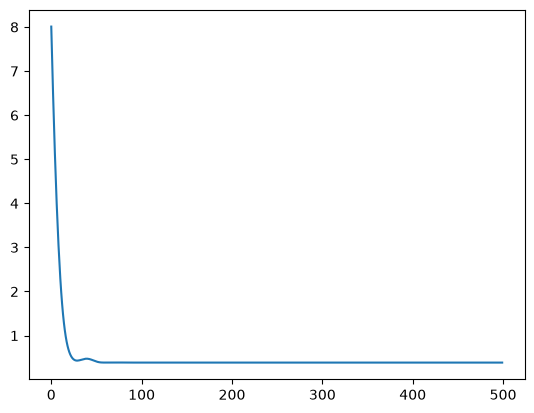

In [123]:
plt.plot(losses)

In [124]:
with torch.inference_mode():
    pred = model(x)


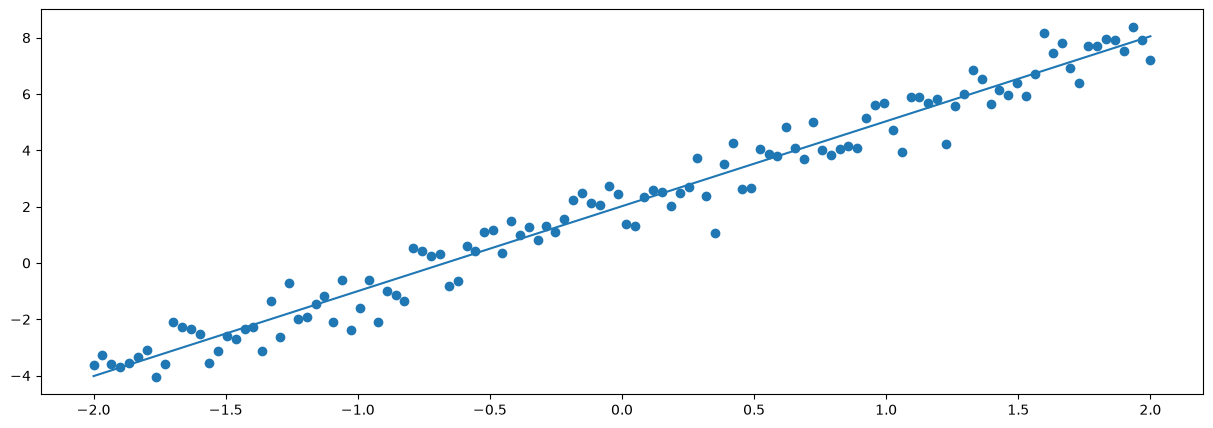

In [125]:
plt.figure(figsize=(15,5)) 
plt.scatter(x,y)
plt.plot(x, pred )

In [126]:
from torcheval.metrics import R2Score

In [127]:
r2_score = R2Score()
r2_score.update(y, pred)
score = r2_score.compute()

In [128]:
print(score)

tensor(0.9686)
